# Personality Analysis

Sklearn can be very useful for data analysis in Python/Jupyter

## Information obtained from Kaggle

#### Project done by Miguel Estrada

In [1]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
# Import SMOTE
from imblearn.over_sampling import SMOTE

In [3]:
#Importing the data
data_personality = pd.read_csv('personality_dataset.csv')
data_personality.head(2)

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert


In [4]:
extrovert_people = data_personality[data_personality['Personality'] == 'Extrovert']
introvert_people = data_personality[data_personality['Personality'] == 'Introvert']

print("Comparisons:")
print("Extroverts: friends circle size -> ", extrovert_people['Friends_circle_size'].mean())
print("Introverts: friends circle size -> ", introvert_people['Friends_circle_size'].mean())
print("Comparisons:")
print("Extroverts: how much do they go outside -> ", extrovert_people['Going_outside'].mean())
print("Introverts: how much do they go outside -> ", introvert_people['Going_outside'].mean())

Comparisons:
Extroverts: friends circle size ->  9.1736733287388
Introverts: friends circle size ->  3.196793002915452
Comparisons:
Extroverts: how much do they go outside ->  4.634615384615385
Introverts: how much do they go outside ->  1.2728592162554426


In [5]:
data_personality.isna().sum()

Time_spent_Alone             63
Stage_fear                   73
Social_event_attendance      62
Going_outside                66
Drained_after_socializing    52
Friends_circle_size          77
Post_frequency               65
Personality                   0
dtype: int64

In [6]:
data_personality.dropna(inplace=True)

In [7]:
data_personality.isnull().sum()

Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
Personality                  0
dtype: int64

In [8]:
data_personality.describe()

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2477.000000,2477.000000,2477.000000,2477.000000,2477.000000
mean,4.522406,3.939039,3.013726,6.239806,3.559548
std,3.491162,2.900044,2.257239,4.311365,2.927397
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,1.000000,3.000000,1.000000
50%,4.000000,3.000000,3.000000,5.000000,3.000000
75%,8.000000,6.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


In [9]:
data_personality['Personality'].value_counts()

Personality
Extrovert    1274
Introvert    1203
Name: count, dtype: int64

In [10]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
data_personality.Personality = labelencoder.fit_transform(data_personality.Personality.values)
data_personality.Drained_after_socializing = labelencoder.fit_transform(data_personality.Drained_after_socializing.values)
data_personality.Stage_fear = labelencoder.fit_transform(data_personality.Stage_fear.values)

Text(0.5, 1.0, 'Personality and Stage fear')

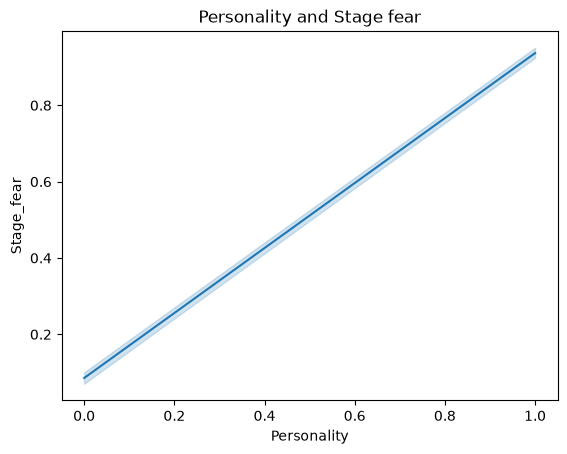

In [11]:
sns.lineplot(data=data_personality, x='Personality', y='Stage_fear')
plt.title("Personality and Stage fear")

Text(0.5, 1.0, 'Correlation among columns/variables')

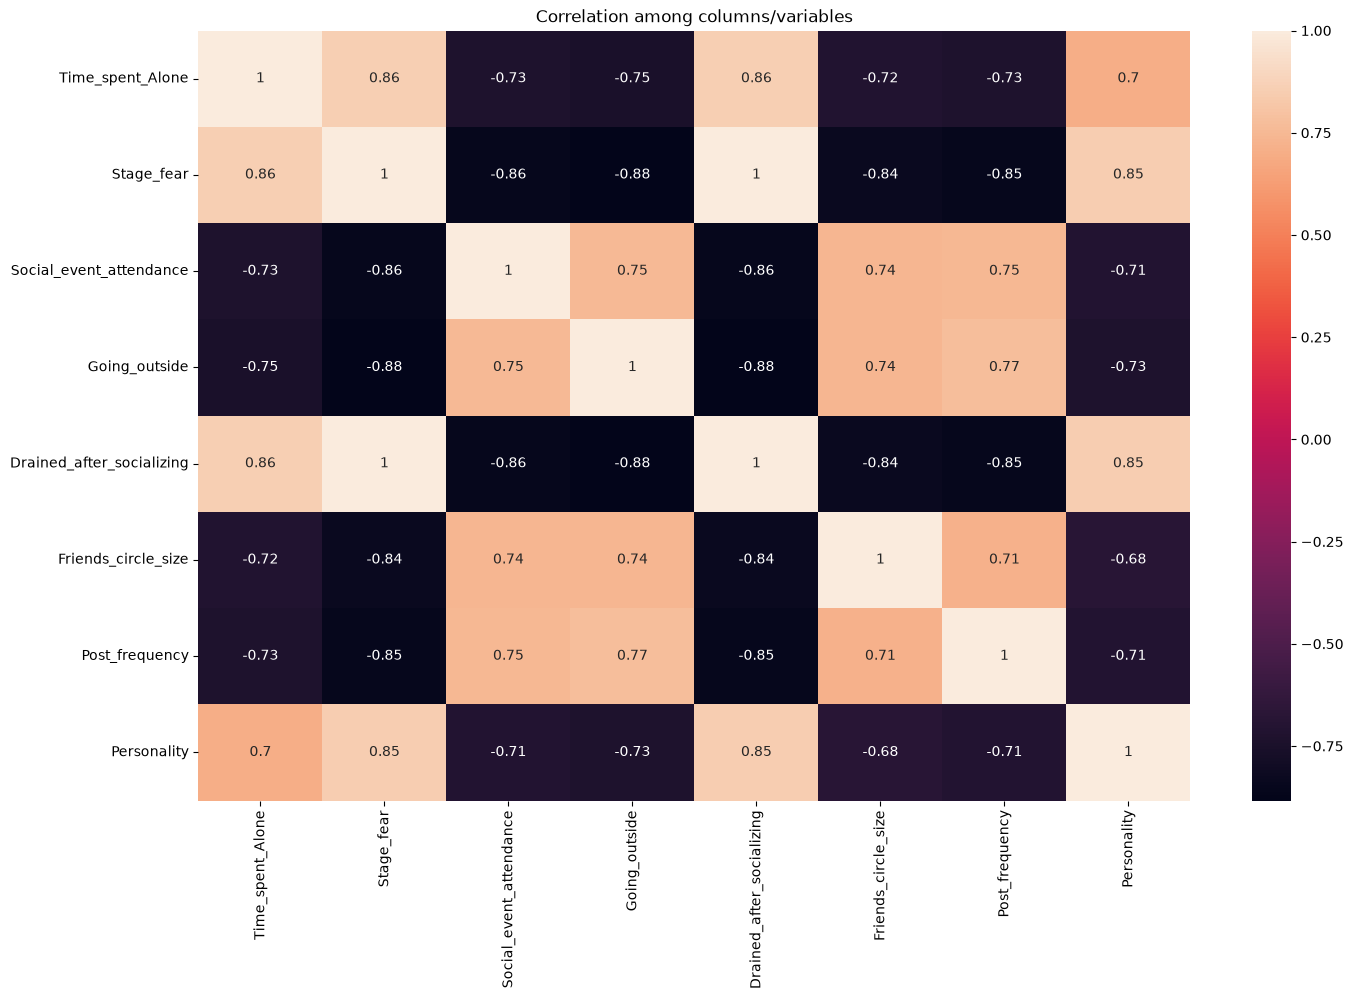

In [12]:
plt.figure(figsize=(16, 10))
sns.heatmap(data_personality.corr(), annot=True)
plt.title('Correlation among columns/variables')

### Graphics

In [13]:
sns.set_theme(style="whitegrid", palette="muted")

# 1. Load dataset
df = pd.read_csv("personality_dataset.csv")
palette_map = {"Extrovert": "#4C72B0", "Introvert": "#DD8452"}
order_p = ["Extrovert", "Introvert"]

C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_21552\1151383908.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_21552\1151383908.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_21552\1151383908.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_21552\1151383908.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v

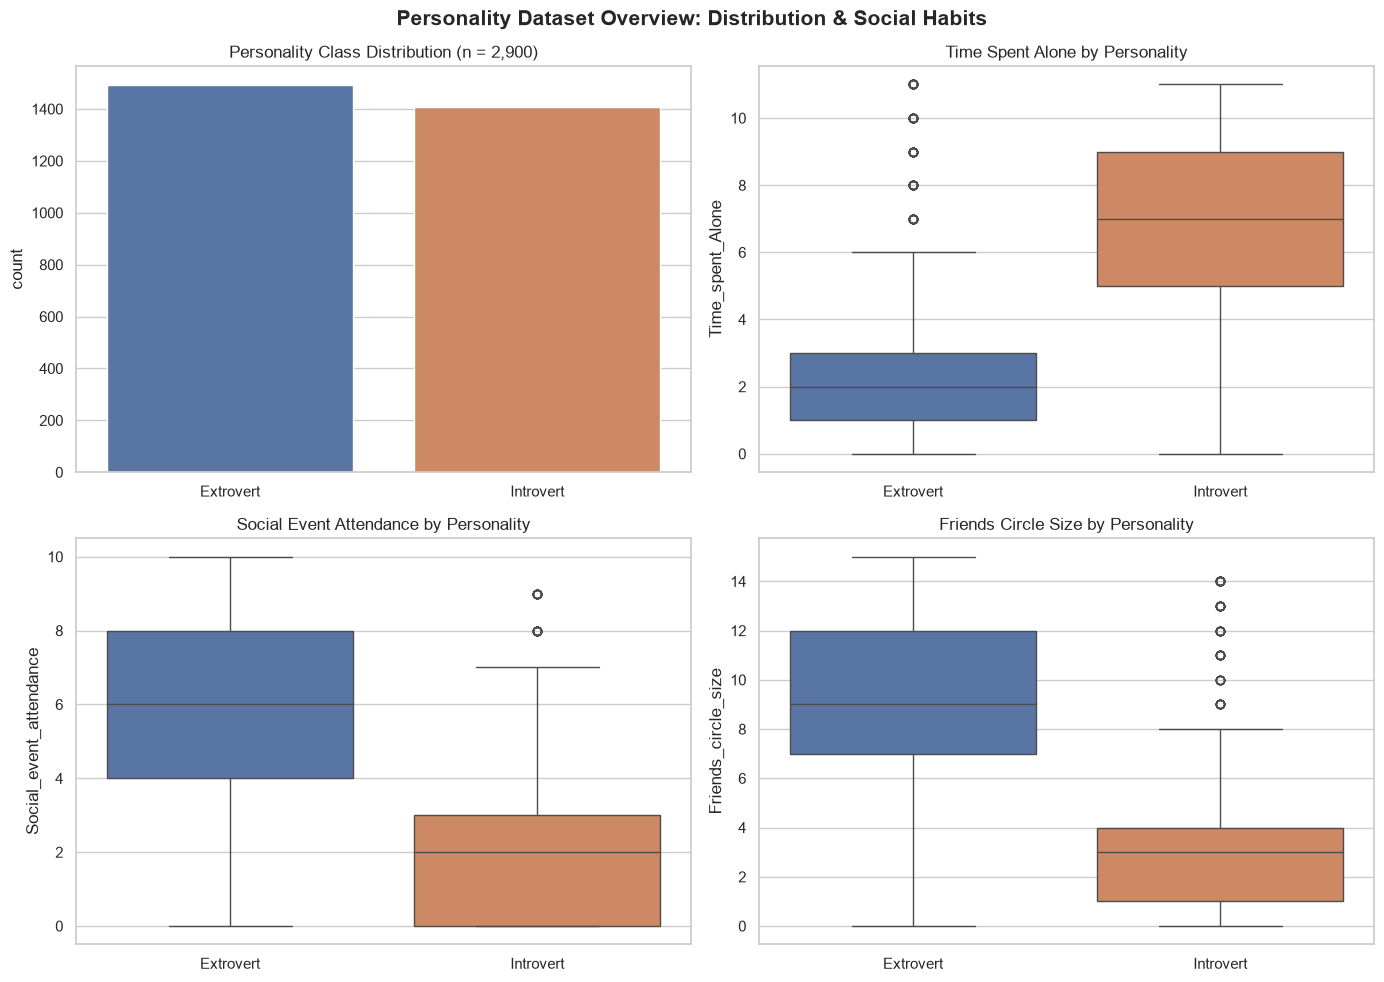

In [14]:
# 2. Overview: target countplot + key numeric boxplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Personality Dataset Overview: Distribution & Social Habits",
    fontsize=15,
    fontweight="bold",
)

sns.countplot(
    data=df, x="Personality", order=order_p, palette=palette_map, ax=axes[0, 0]
)
axes[0, 0].set_title("Personality Class Distribution (n = 2,900)")
axes[0, 0].set_xlabel("")

sns.boxplot(
    data=df,
    x="Personality",
    y="Time_spent_Alone",
    order=order_p,
    palette=palette_map,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Time Spent Alone by Personality")
axes[0, 1].set_xlabel("")

sns.boxplot(
    data=df,
    x="Personality",
    y="Social_event_attendance",
    order=order_p,
    palette=palette_map,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Social Event Attendance by Personality")
axes[1, 0].set_xlabel("")

sns.boxplot(
    data=df,
    x="Personality",
    y="Friends_circle_size",
    order=order_p,
    palette=palette_map,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Friends Circle Size by Personality")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()


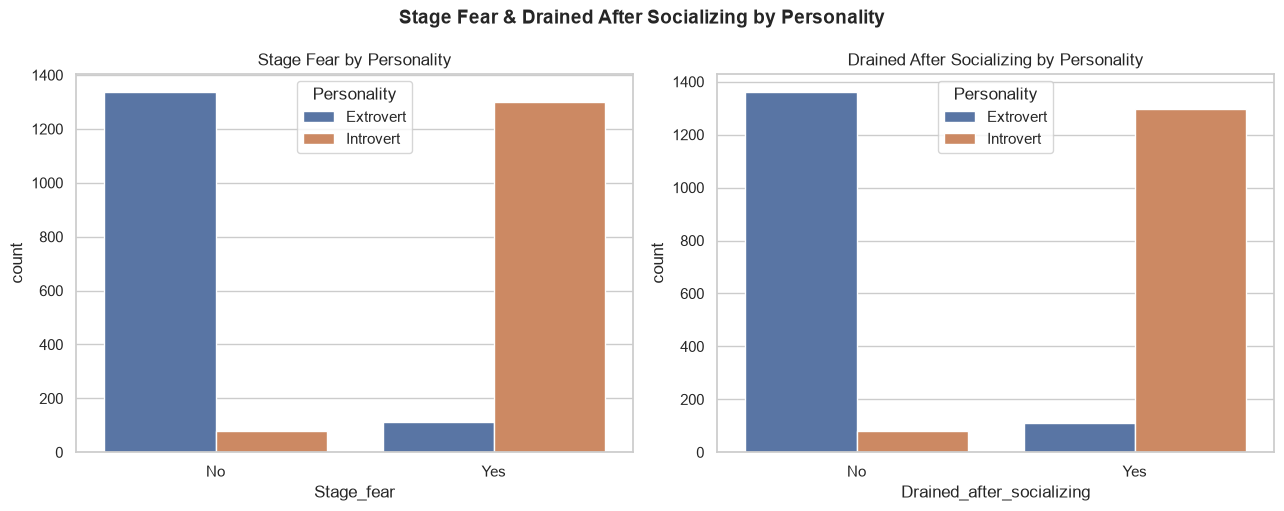

In [15]:
# 3. Categorical indicators by Personality
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
fig.suptitle(
    "Stage Fear & Drained After Socializing by Personality",
    fontsize=14,
    fontweight="bold",
)

sns.countplot(
    data=df,
    x="Stage_fear",
    hue="Personality",
    hue_order=order_p,
    palette=palette_map,
    ax=axes[0],
)
axes[0].set_title("Stage Fear by Personality")

sns.countplot(
    data=df,
    x="Drained_after_socializing",
    hue="Personality",
    hue_order=order_p,
    palette=palette_map,
    ax=axes[1],
)
axes[1].set_title("Drained After Socializing by Personality")

plt.tight_layout()
plt.show()

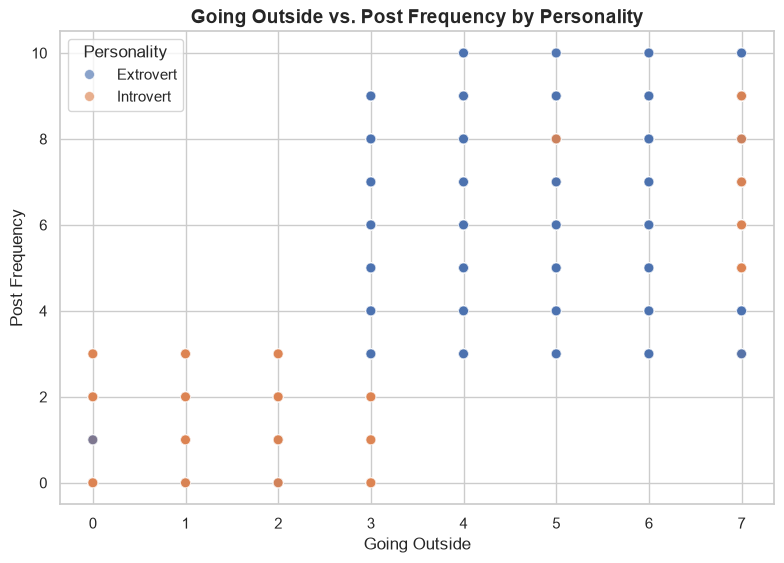

In [16]:
plt.figure(figsize=(8, 5.8))
sns.scatterplot(
    data=df,
    x="Going_outside",
    y="Post_frequency",
    hue="Personality",
    hue_order=order_p,
    palette=palette_map,
    alpha=0.65,
    s=50,
)
plt.title(
    "Going Outside vs. Post Frequency by Personality",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Going Outside")
plt.ylabel("Post Frequency")
plt.legend(title="Personality")

plt.tight_layout()
plt.show()

#### Preparing data for Logistic Regression
Used for predicting the personality

In [17]:
X = data_personality.drop('Personality', axis=1)
Y = data_personality['Personality']

In [18]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

In [19]:
classifier = LogisticRegression(
    fit_intercept=True,
    max_iter=1000,
    random_state=42
)

# Apply SMOTE only to the training data to avoid data leakage.
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

classifier.fit(x_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [20]:
predictions = classifier.predict(x_test)

<Axes: >

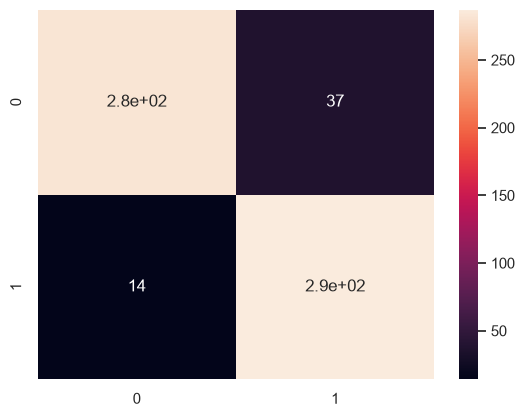

In [21]:
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True)

In [22]:
## Accuracy of the model
accuracy_score(y_test, predictions)

0.917741935483871

In [23]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.88      0.92       319
           1       0.89      0.95      0.92       301

    accuracy                           0.92       620
   macro avg       0.92      0.92      0.92       620
weighted avg       0.92      0.92      0.92       620



In [24]:
# Balanced accuracy is useful when class frequencies are not exactly equal.
balanced_accuracy = balanced_accuracy_score(y_test, predictions)
print("Balanced Accuracy: {:.4f}".format(balanced_accuracy))

Balanced Accuracy: 0.9188


## Feature importance: which variables best predict personality?

This section evaluates **all input variables** used by the Logistic Regression model.

- **Permutation importance (ROC-AUC)** measures how much the model's ability to rank the two classes decreases when one feature is randomly shuffled. This is the primary ranking because it evaluates predicted probabilities/scores, not only hard class labels.
- **Permutation importance (balanced accuracy)** provides a second perspective based on class-balanced classification performance.
- **Logistic Regression coefficients** show the direction and strength of each feature's relationship with the model prediction. Because the inputs were standardized, coefficient magnitudes are on a comparable scale.

The analysis uses the held-out test set. SMOTE is applied only to the training set. A feature can legitimately have zero or negative permutation importance; the notebook does not force nonzero values. Correlated features may also share importance.

In [25]:
# Keep the original column names for the importance results.
feature_names = X.columns

# ROC-AUC evaluates predicted scores/probabilities, so it can reveal
# feature contributions that hard-label accuracy may miss.
permutation_auc = permutation_importance(
    classifier,
    x_test,
    y_test,
    n_repeats=50,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

permutation_balanced = permutation_importance(
    classifier,
    x_test,
    y_test,
    n_repeats=50,
    random_state=42,
    scoring="balanced_accuracy",
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "ROC_AUC_Importance": permutation_auc.importances_mean,
    "ROC_AUC_Std": permutation_auc.importances_std,
    "Balanced_Accuracy_Importance": permutation_balanced.importances_mean,
    "Balanced_Accuracy_Std": permutation_balanced.importances_std
}).sort_values("ROC_AUC_Importance", ascending=False)

display(permutation_importance_df)

,Feature,ROC_AUC_Importance,ROC_AUC_Std,Balanced_Accuracy_Importance,Balanced_Accuracy_Std
1,Stage_fear,0.235382,0.020551,0.419644,0.020505
4,Drained_after_socializing,0.235382,0.020551,0.419644,0.020505
0,Time_spent_Alone,0.017753,0.005578,0.000000,0.000000
5,Friends_circle_size,0.014344,0.005217,0.000000,0.000000
3,Going_outside,0.011047,0.004333,0.000000,0.000000
2,Social_event_attendance,0.005079,0.003397,0.000000,0.000000
6,Post_frequency,0.000113,0.000368,0.000000,0.000000


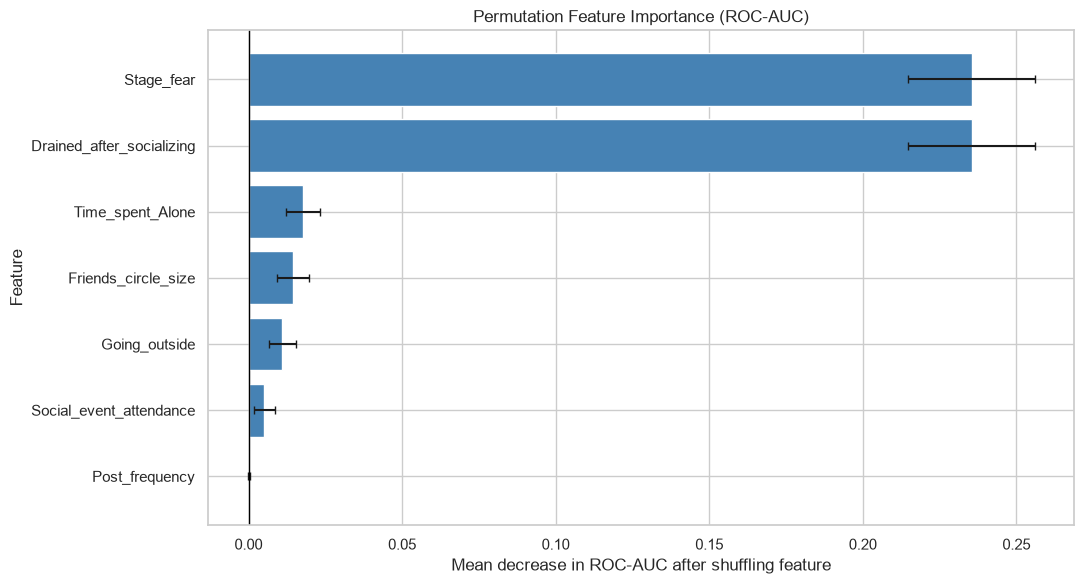

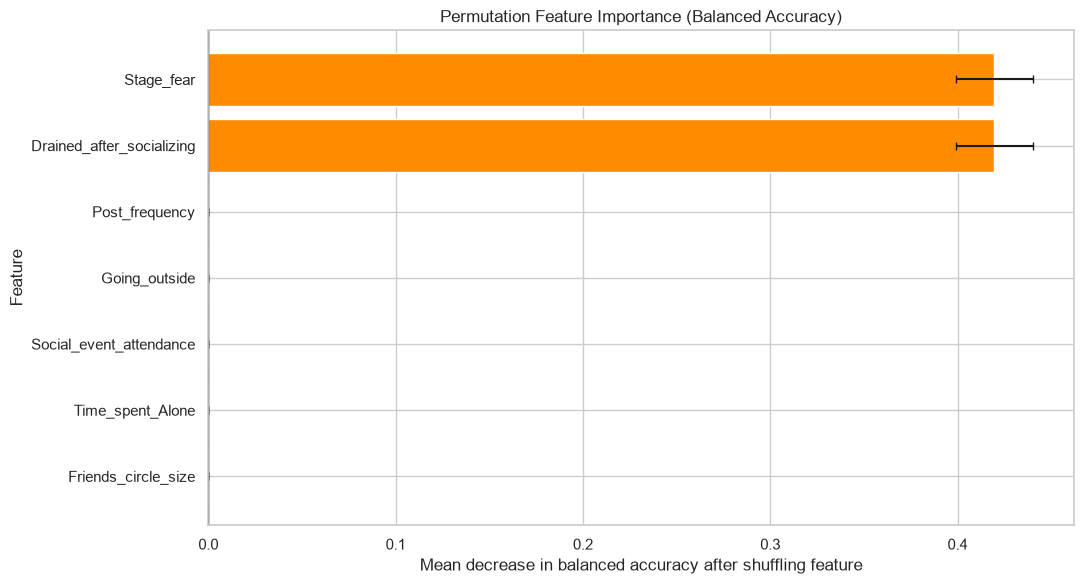

In [26]:
# Plot permutation importance for EVERY feature (not only the top few).
# Error bars show variability across the repeated shuffles.
plot_auc = permutation_importance_df.sort_values("ROC_AUC_Importance", ascending=True)

plt.figure(figsize=(11, max(6, len(plot_auc) * 0.55)))
plt.barh(
    plot_auc["Feature"],
    plot_auc["ROC_AUC_Importance"],
    xerr=plot_auc["ROC_AUC_Std"],
    capsize=3,
    color="steelblue"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Permutation Feature Importance (ROC-AUC)")
plt.xlabel("Mean decrease in ROC-AUC after shuffling feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# A second graph using balanced accuracy as the scoring metric.
plot_balanced = permutation_importance_df.sort_values(
    "Balanced_Accuracy_Importance", ascending=True
)

plt.figure(figsize=(11, max(6, len(plot_balanced) * 0.55)))
plt.barh(
    plot_balanced["Feature"],
    plot_balanced["Balanced_Accuracy_Importance"],
    xerr=plot_balanced["Balanced_Accuracy_Std"],
    capsize=3,
    color="darkorange"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Permutation Feature Importance (Balanced Accuracy)")
plt.xlabel("Mean decrease in balanced accuracy after shuffling feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [27]:
# Logistic Regression coefficients.
# For binary classification, a positive coefficient moves the prediction
# toward the class encoded as 1; a negative coefficient moves it toward class 0.
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": classifier.coef_[0],
    "Absolute_Coefficient": np.abs(classifier.coef_[0])
}).sort_values("Absolute_Coefficient", ascending=False)

display(coefficient_df)

,Feature,Coefficient,Absolute_Coefficient
1,Stage_fear,4.061770,4.061770
4,Drained_after_socializing,4.061770,4.061770
3,Going_outside,0.184620,0.184620
0,Time_spent_Alone,-0.135784,0.135784
5,Friends_circle_size,0.122351,0.122351
2,Social_event_attendance,0.098824,0.098824
6,Post_frequency,0.009757,0.009757


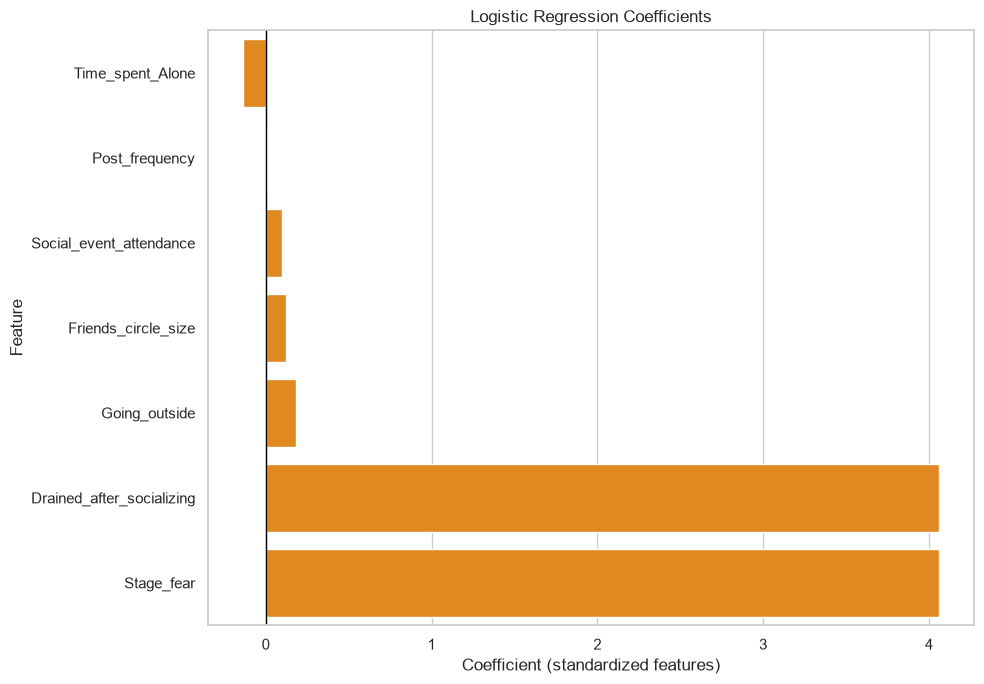

In [28]:
# Plot signed coefficients to show both magnitude and direction.
coefficient_plot = coefficient_df.sort_values("Coefficient")

plt.figure(figsize=(10, 7))
sns.barplot(
    data=coefficient_plot,
    x="Coefficient",
    y="Feature",
    color="darkorange"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (standardized features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [29]:
# Compare both permutation metrics and Logistic Regression coefficient magnitude.
importance_comparison = permutation_importance_df[
    ["Feature", "ROC_AUC_Importance", "Balanced_Accuracy_Importance"]
].merge(
    coefficient_df[["Feature", "Coefficient", "Absolute_Coefficient"]],
    on="Feature"
).sort_values("ROC_AUC_Importance", ascending=False)

display(importance_comparison)

,Feature,ROC_AUC_Importance,Balanced_Accuracy_Importance,Coefficient,Absolute_Coefficient
0,Stage_fear,0.235382,0.419644,4.061770,4.061770
1,Drained_after_socializing,0.235382,0.419644,4.061770,4.061770
2,Time_spent_Alone,0.017753,0.000000,-0.135784,0.135784
3,Friends_circle_size,0.014344,0.000000,0.122351,0.122351
4,Going_outside,0.011047,0.000000,0.184620,0.184620
5,Social_event_attendance,0.005079,0.000000,0.098824,0.098824
6,Post_frequency,0.000113,0.000000,0.009757,0.009757


### How to interpret the results

1. **ROC-AUC permutation importance** is the primary ranking. A larger positive value means shuffling that feature reduced the model's ability to distinguish the two personality classes.
2. **Balanced-accuracy permutation importance** is a second performance-based ranking. Comparing it with ROC-AUC helps reveal whether a feature affects ranking quality, class decisions, or both.
3. **Error bars** show the standard deviation across repeated shuffles. Large error bars indicate that the estimated importance is less stable.
4. **Zero or negative importance is possible.** A zero can mean that shuffling the variable did not measurably change the selected test metric. A negative value can occur from sampling variability or because the model performs slightly better after shuffling that feature. Do not force these values to be positive.
5. **Absolute coefficient size** describes the strength of the model's learned linear relationship after standardization. The signed coefficient indicates direction relative to the class encoded as `1`.
6. If the rankings differ, that is not necessarily an error: permutation importance measures impact on model performance, while coefficients describe the fitted linear model. Correlated variables can share or mask importance.
7. These are associations used by this model, not proof that a variable causes a personality type.